# Step 1 Data Preparation

In [388]:
import os
import time
import platform
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    log_loss,
    confusion_matrix,
    precision_recall_curve
)

RANDOM_STATE = 42

# Load dataset
df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Explore

In [389]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Data types
print("\nData types:")
print(df.dtypes.value_counts())

# Column information
print("\nColumn information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget proportions:")
print(df["y"].value_counts(normalize=True))

# Positive-class proportion
positive_proportion = (df["y"] == "yes").mean()
print(f"\nPositive-class proportion: {positive_proportion:.4%}")

Number of rows: 41188
Number of columns: 21

Data types:
object     11
int64       5
float64     5
Name: count, dtype: int64

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        4118

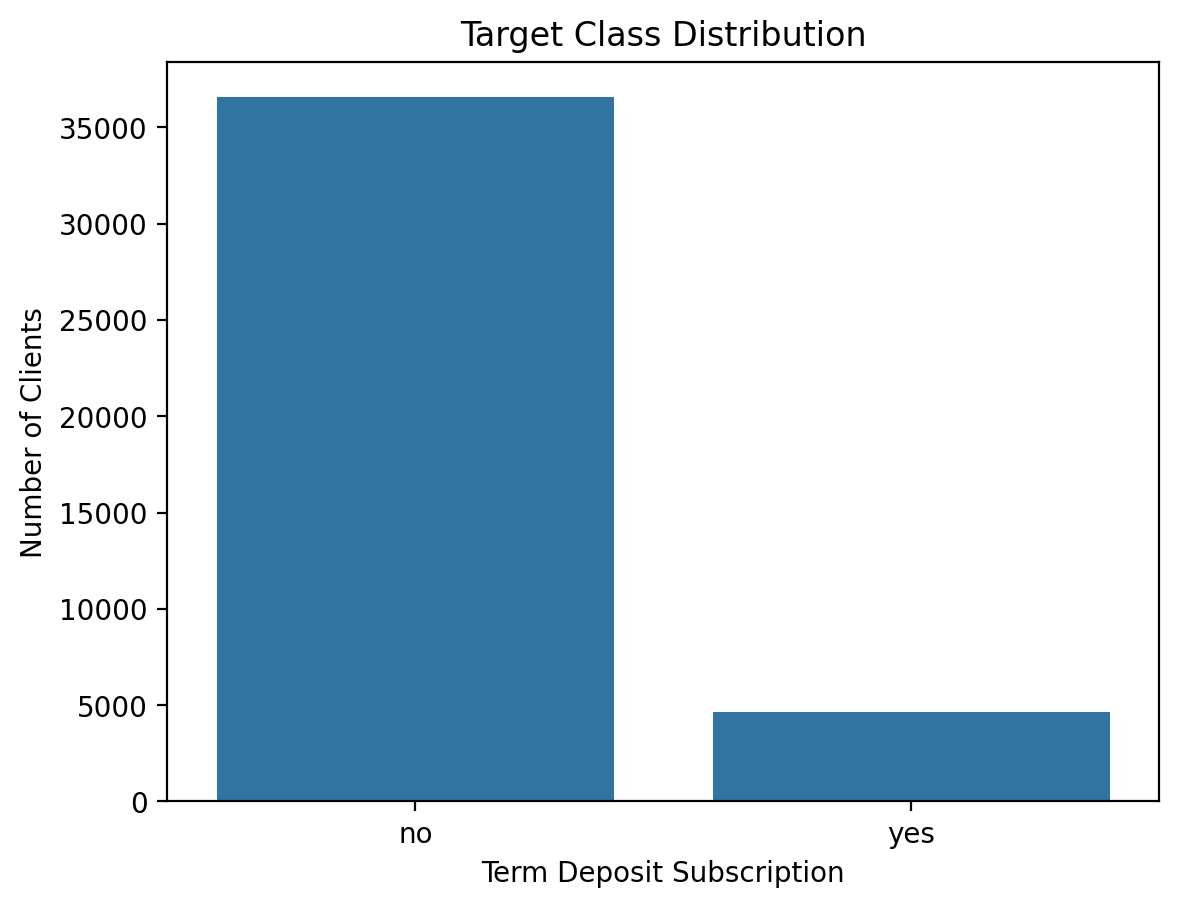

In [390]:
sns.countplot(data=df, x="y")

plt.title("Target Class Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Clients")
plt.show()

## Unknown categorical values

In [391]:
categorical_cols = df.select_dtypes(include="object").columns.drop("y")

print("Unknown categorical values:\n")

for col in categorical_cols:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(f"{col}: {count} ({count / len(df):.2%})")

Unknown categorical values:

job: 330 (0.80%)
marital: 80 (0.19%)
education: 1731 (4.20%)
default: 8597 (20.87%)
housing: 990 (2.40%)
loan: 990 (2.40%)


In [392]:
print("Number of pdays = 999:", (df["pdays"] == 999).sum())
print(
    "Percentage of pdays = 999:",
    f"{(df['pdays'] == 999).mean():.2%}"
)

Number of pdays = 999: 39673
Percentage of pdays = 999: 96.32%


## Clean the dataset

In [393]:
# Create indicator for whether the client was previously contacted
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

# Replace special value 999 with NaN
df["pdays"] = df["pdays"].replace(999, np.nan)

# Remove duration 
df = df.drop(columns=["duration"])

# Separate predictors and target
X = df.drop(columns=["y"])
y = (df["y"] == "yes").astype(int)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))

Predictor shape: (41188, 20)
Target shape: (41188,)

Target distribution:
y
0    0.887346
1    0.112654
Name: proportion, dtype: float64


## Create train/validation/test splits

In [394]:
# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# Display split sizes
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (28831, 20)
Validation set: (6178, 20)
Test set: (6179, 20)


## Check class proportion

In [395]:
split_summary = pd.DataFrame({
    "Dataset": ["Overall", "Training", "Validation", "Test"],
    "Rows": [len(y), len(y_train), len(y_val), len(y_test)],
    "Positive Class Proportion": [
        y.mean(),
        y_train.mean(),
        y_val.mean(),
        y_test.mean()
    ]
})

split_summary["Positive Class Proportion"] = (
    split_summary["Positive Class Proportion"].map(lambda x: f"{x:.4%}")
)

display(split_summary)

,Dataset,Rows,Positive Class Proportion
0,Overall,41188,11.2654%
1,Training,28831,11.2657%
2,Validation,6178,11.2658%
3,Test,6179,11.2640%


## Preprocessing

In [396]:
# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 10
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Categorical features: 10
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [397]:
# Numerical preprocessing for GBDT
numeric_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Numerical preprocessing for MLP
numeric_mlp = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# GBDT preprocessing
preprocessor_gbdt = ColumnTransformer([
    ("num", numeric_tree, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# MLP preprocessing
preprocessor_mlp = ColumnTransformer([
    ("num", numeric_mlp, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [398]:
# GBDT preprocessing
X_train_gbdt = preprocessor_gbdt.fit_transform(X_train)
X_val_gbdt = preprocessor_gbdt.transform(X_val)
X_test_gbdt = preprocessor_gbdt.transform(X_test)

# MLP preprocessing
X_train_mlp = preprocessor_mlp.fit_transform(X_train)
X_val_mlp = preprocessor_mlp.transform(X_val)
X_test_mlp = preprocessor_mlp.transform(X_test)

print("GBDT transformed shapes:")
print("Training:", X_train_gbdt.shape)
print("Validation:", X_val_gbdt.shape)
print("Test:", X_test_gbdt.shape)

print("\nMLP transformed shapes:")
print("Training:", X_train_mlp.shape)
print("Validation:", X_val_mlp.shape)
print("Test:", X_test_mlp.shape)

GBDT transformed shapes:
Training: (28831, 63)
Validation: (6178, 63)
Test: (6179, 63)

MLP transformed shapes:
Training: (28831, 63)
Validation: (6178, 63)
Test: (6179, 63)


# Step 2 Gradient Boosted Trees (GBDT)

## Define the function

In [399]:
def run_gbdt_experiment(
    experiment_name,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    reg_lambda=1.0
):
    model = xgb.XGBClassifier(
        n_estimators=3000,
        learning_rate=learning_rate,
        max_depth=max_depth,
        subsample=subsample,
        reg_lambda=reg_lambda,
        tree_method="hist",
        eval_metric="logloss",
        early_stopping_rounds=30,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    start_time = time.perf_counter()

    model.fit(
        X_train_gbdt,
        y_train,
        eval_set=[
            (X_train_gbdt, y_train),
            (X_val_gbdt, y_val)
        ],
        verbose=False
    )
    fit_time = time.perf_counter() - start_time

    # Validation predictions
    val_probabilities = model.predict_proba(X_val_gbdt)[:, 1]
    # Validation metrics
    val_ap = average_precision_score(
        y_val, val_probabilities
    )
    val_logloss = log_loss(
        y_val, val_probabilities
    )
    results = {
        "experiment": experiment_name,
        "learning_rate": learning_rate,
        "max_depth": max_depth,
        "subsample": subsample,
        "reg_lambda": reg_lambda,
        "best_iteration": model.best_iteration,
        "validation_AP": val_ap,
        "validation_logloss": val_logloss,
        "fit_time_seconds": fit_time
    }
    return model, results

## Compare learning rates

In [400]:
gbdt_models = {}
gbdt_results = []

learning_rates = [0.01, 0.1, 0.3]

for lr in learning_rates:

    name = f"learning_rate_{lr}"

    model, results = run_gbdt_experiment(
        experiment_name=name,
        learning_rate=lr,
        max_depth=3,
        subsample=0.8
    )

    gbdt_models[name] = model
    gbdt_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Best iteration = {results['best_iteration']}, "
        f"Time = {results['fit_time_seconds']:.2f}s"
    )

learning_rate_0.01: AP = 0.4884, Best iteration = 1019, Time = 2.46s
learning_rate_0.1: AP = 0.4914, Best iteration = 254, Time = 0.65s
learning_rate_0.3: AP = 0.4854, Best iteration = 39, Time = 0.18s


## Compare Tree Depth

In [401]:
max_depths = [2, 4, 6]

for depth in max_depths:

    name = f"max_depth_{depth}"

    model, results = run_gbdt_experiment(
        experiment_name=name,
        learning_rate=0.1,
        max_depth=depth,
        subsample=0.8
    )

    gbdt_models[name] = model
    gbdt_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Best iteration = {results['best_iteration']}, "
        f"Time = {results['fit_time_seconds']:.2f}s"
    )

max_depth_2: AP = 0.4838, Best iteration = 288, Time = 0.76s
max_depth_4: AP = 0.4893, Best iteration = 118, Time = 0.40s
max_depth_6: AP = 0.4920, Best iteration = 41, Time = 0.25s


## Compare regularization (subsample)

The baseline (learning_rate=0.1, max_depth=3, subsample=0.8) was already trained as `learning_rate_0.1`, so subsample=0.8 is not re-run here (it would be an exact duplicate). Likewise, max_depth=3 in the depth comparison is that same baseline.

In [402]:
subsample_values = [0.6, 1.0]  

for sample in subsample_values:

    name = f"subsample_{sample}"

    model, results = run_gbdt_experiment(
        experiment_name=name,
        learning_rate=0.1,
        max_depth=3,
        subsample=sample
    )

    gbdt_models[name] = model
    gbdt_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Best iteration = {results['best_iteration']}, "
        f"Time = {results['fit_time_seconds']:.2f}s"
    )

subsample_0.6: AP = 0.4879, Best iteration = 212, Time = 0.69s
subsample_1.0: AP = 0.4937, Best iteration = 189, Time = 0.51s


## Compare all

In [403]:
gbdt_results_df = pd.DataFrame(gbdt_results)

gbdt_results_df = gbdt_results_df.sort_values(
    by="validation_AP",
    ascending=False
).reset_index(drop=True)

display(
    gbdt_results_df.round(4)
)

,experiment,learning_rate,max_depth,subsample,reg_lambda,best_iteration,validation_AP,validation_logloss,fit_time_seconds
0,subsample_1.0,0.10,3,1.0,1.0,189,0.4937,0.2663,0.5077
1,max_depth_6,0.10,6,0.8,1.0,41,0.4920,0.2652,0.2494
2,learning_rate_0.1,0.10,3,0.8,1.0,254,0.4914,0.2659,0.6549
3,max_depth_4,0.10,4,0.8,1.0,118,0.4893,0.2662,0.3973
4,learning_rate_0.01,0.01,3,0.8,1.0,1019,0.4884,0.2672,2.4621
5,subsample_0.6,0.10,3,0.6,1.0,212,0.4879,0.2665,0.6928
6,learning_rate_0.3,0.30,3,0.8,1.0,39,0.4854,0.2678,0.1758
7,max_depth_2,0.10,2,0.8,1.0,288,0.4838,0.2669,0.7595


## Select the best model

In [404]:
best_gbdt_result = gbdt_results_df.iloc[0]

best_gbdt_name = best_gbdt_result["experiment"]
best_gbdt_model = gbdt_models[best_gbdt_name]

print("Best GBDT configuration:")
print(best_gbdt_result)

print("\nSelected model:", best_gbdt_name)
print("Best boosting iteration:", best_gbdt_model.best_iteration)

Best GBDT configuration:
experiment            subsample_1.0
learning_rate                   0.1
max_depth                         3
subsample                       1.0
reg_lambda                      1.0
best_iteration                  189
validation_AP              0.493672
validation_logloss         0.266273
fit_time_seconds           0.507723
Name: 0, dtype: object

Selected model: subsample_1.0
Best boosting iteration: 189


## Plot training vs validation log loss

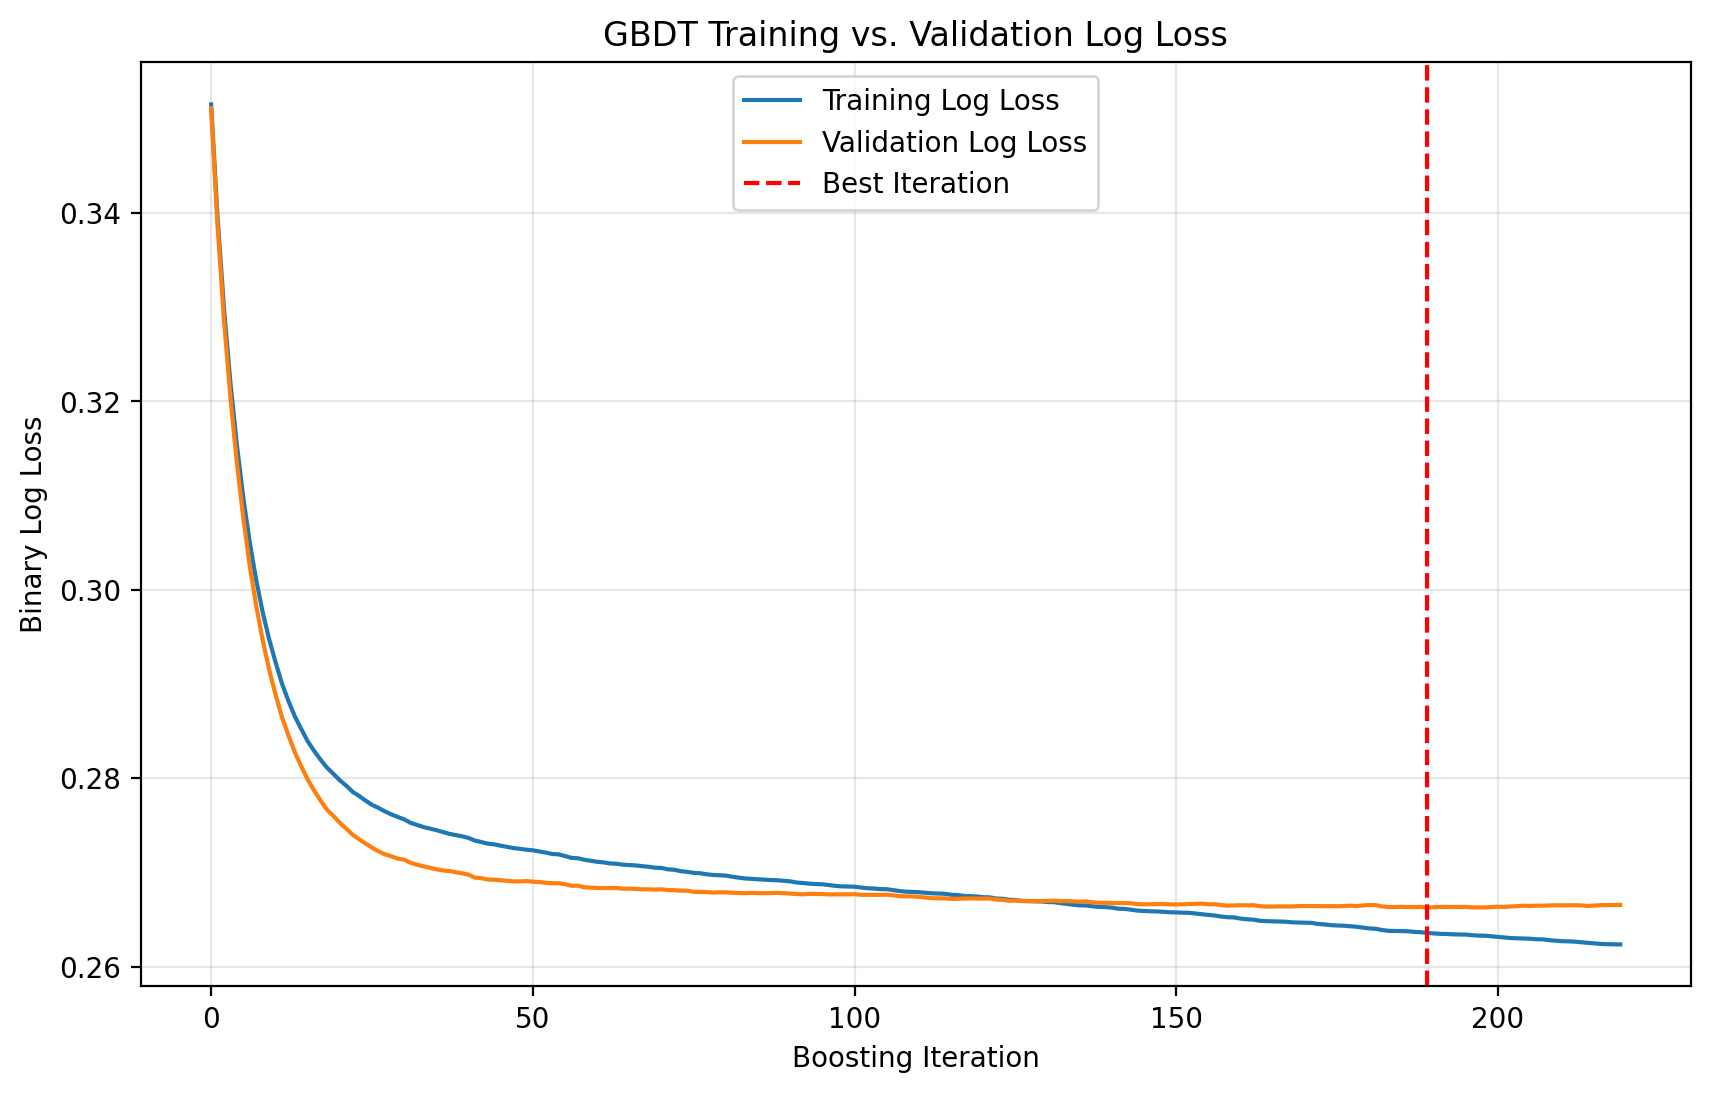

In [405]:
evals_result = best_gbdt_model.evals_result()

train_loss = evals_result["validation_0"]["logloss"]
val_loss = evals_result["validation_1"]["logloss"]

plt.figure(figsize=(10, 6))

plt.plot(train_loss, label="Training Log Loss")
plt.plot(val_loss, label="Validation Log Loss")

plt.axvline(
    best_gbdt_model.best_iteration,
    color="red",
    linestyle="--",
    label="Best Iteration"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Binary Log Loss")
plt.title("GBDT Training vs. Validation Log Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Plot Feature Importance

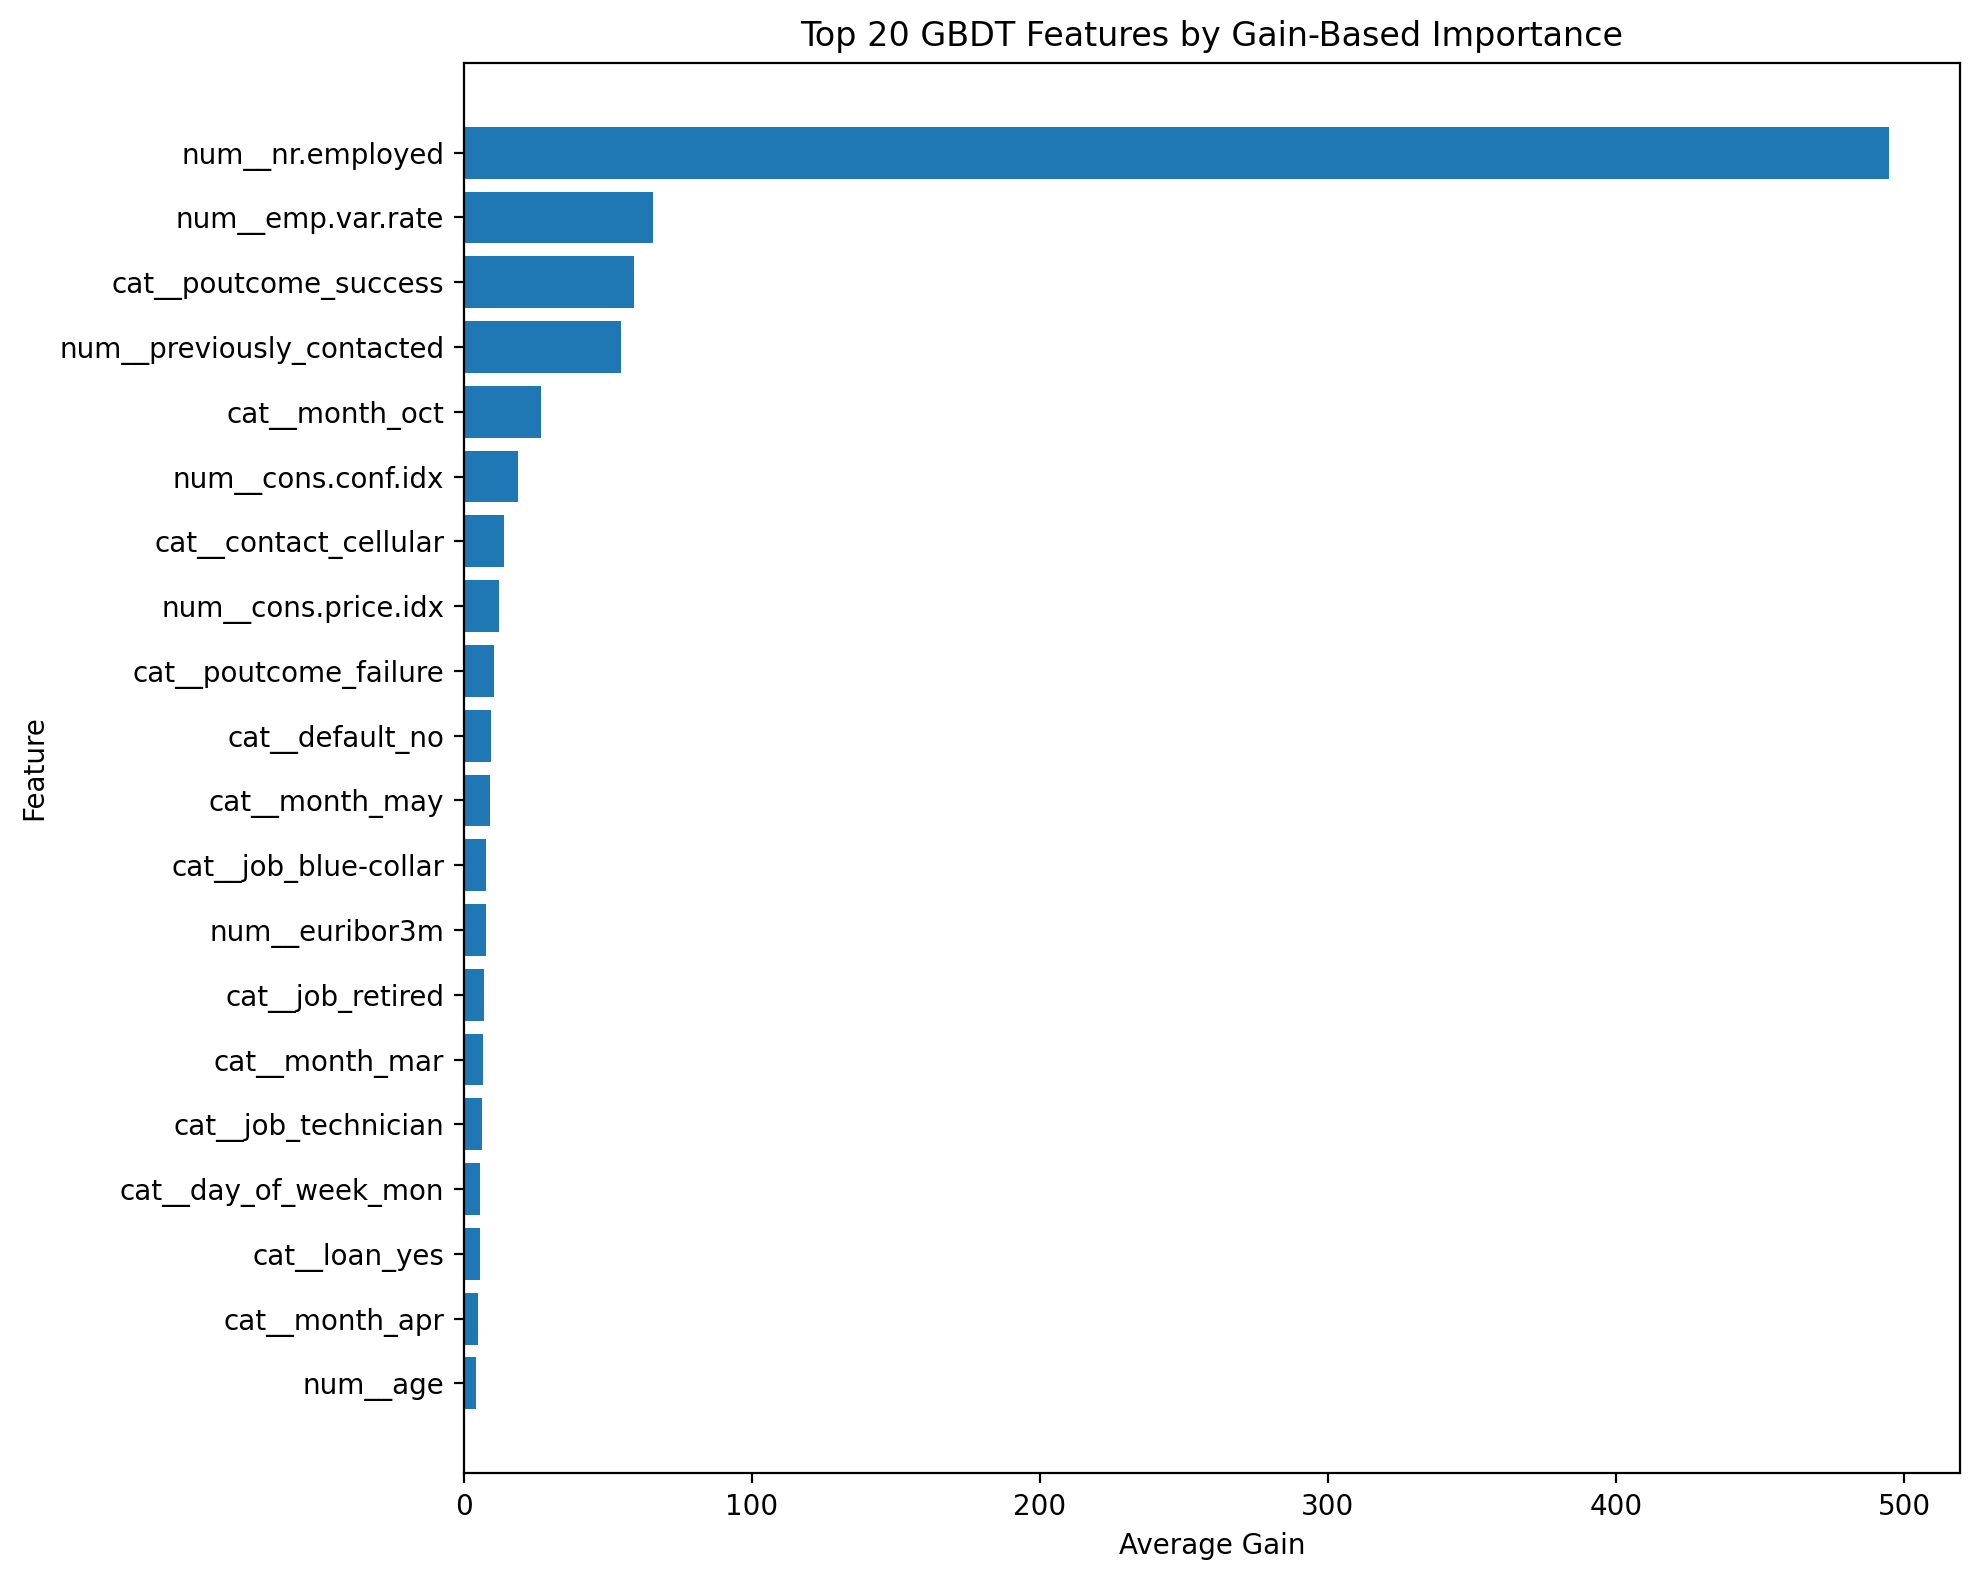

In [406]:
# Get transformed feature names
feature_names = preprocessor_gbdt.get_feature_names_out()

# Retrieve gain-based importance
importance_dict = best_gbdt_model.get_booster().get_score(
    importance_type="gain"
)

# Include features with zero importance
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": [
        importance_dict.get(f"f{i}", 0)
        for i in range(len(feature_names))
    ]
})

importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

# Plot top 20 features
top_features = importance_df.head(20).sort_values(
    by="importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Average Gain")
plt.ylabel("Feature")
plt.title("Top 20 GBDT Features by Gain-Based Importance")
plt.tight_layout()
plt.show()

# Step 3 Multi-Layer Perceptron (MLP)

## Define a function

In [407]:
def run_mlp_experiment(
    experiment_name,
    hidden_layer_sizes=(128, 64),
    learning_rate_init=0.001,
    alpha=0.0001
):

    model = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        learning_rate_init=learning_rate_init,
        alpha=alpha,
        max_iter=225,          
        batch_size=1024,
        early_stopping=False,
        random_state=RANDOM_STATE
    )

    # Capture convergence warnings
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        start_time = time.perf_counter()
        model.fit(X_train_mlp, y_train)
        fit_time = time.perf_counter() - start_time

    convergence_warning = any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught_warnings
    )

    # Validation predictions
    val_probabilities = model.predict_proba(X_val_mlp)[:, 1]
    # Validation metrics
    val_ap = average_precision_score(
        y_val, val_probabilities
    )

    val_logloss = log_loss(
        y_val, val_probabilities
    )

    results = {
        "experiment": experiment_name,
        "hidden_layer_sizes": hidden_layer_sizes,
        "learning_rate_init": learning_rate_init,
        "alpha": alpha,
        "n_iter": model.n_iter_,
        "training_loss": model.loss_,
        "validation_AP": val_ap,
        "validation_logloss": val_logloss,
        "fit_time_seconds": fit_time,
        "convergence_warning": convergence_warning
    }
    return model, results

## Compare network architectures

In [408]:
mlp_models = {}
mlp_results = []

architectures = [
    (64,),
    (128, 64),
    (128, 64, 32)
]

for architecture in architectures:

    name = f"architecture_{architecture}"

    model, results = run_mlp_experiment(
        experiment_name=name,
        hidden_layer_sizes=architecture,
        learning_rate_init=0.001,
        alpha=0.0001
    )

    mlp_models[name] = model
    mlp_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Iterations = {results['n_iter']}, "
        f"Time = {results['fit_time_seconds']:.2f}s, "
        f"Convergence warning = {results['convergence_warning']}"
    )

architecture_(64,): AP = 0.4458, Iterations = 225, Time = 18.90s, Convergence warning = True
architecture_(128, 64): AP = 0.3352, Iterations = 225, Time = 40.13s, Convergence warning = True
architecture_(128, 64, 32): AP = 0.3352, Iterations = 225, Time = 37.97s, Convergence warning = True


## Compare Learning Rates

In [409]:
learning_rates_mlp = [0.0003, 0.003, 0.01]

for lr in learning_rates_mlp:

    name = f"learning_rate_{lr}"

    model, results = run_mlp_experiment(
        experiment_name=name,
        hidden_layer_sizes=(128, 64),
        learning_rate_init=lr,
        alpha=0.0001
    )

    mlp_models[name] = model
    mlp_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Iterations = {results['n_iter']}, "
        f"Time = {results['fit_time_seconds']:.2f}s, "
        f"Convergence warning = {results['convergence_warning']}"
    )

learning_rate_0.0003: AP = 0.4218, Iterations = 225, Time = 34.56s, Convergence warning = True
learning_rate_0.003: AP = 0.3040, Iterations = 161, Time = 21.66s, Convergence warning = False
learning_rate_0.01: AP = 0.3302, Iterations = 131, Time = 16.37s, Convergence warning = False


## Compare L2 Reg (alpha)

In [410]:
alpha_values = [0.001, 0.1, 1.0, 5.0]  

for alpha_value in alpha_values:

    name = f"alpha_{alpha_value}"

    model, results = run_mlp_experiment(
        experiment_name=name,
        hidden_layer_sizes=(128, 64),
        learning_rate_init=0.001,
        alpha=alpha_value
    )

    mlp_models[name] = model
    mlp_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Iterations = {results['n_iter']}, "
        f"Time = {results['fit_time_seconds']:.2f}s, "
        f"Convergence warning = {results['convergence_warning']}"
    )

alpha_0.001: AP = 0.3393, Iterations = 225, Time = 31.03s, Convergence warning = True
alpha_0.1: AP = 0.3664, Iterations = 190, Time = 25.49s, Convergence warning = False
alpha_1.0: AP = 0.4777, Iterations = 118, Time = 15.08s, Convergence warning = False
alpha_5.0: AP = 0.4645, Iterations = 74, Time = 8.66s, Convergence warning = False


## Compare all

In [411]:
mlp_results_df = pd.DataFrame(mlp_results)

mlp_results_df = mlp_results_df.sort_values(
    by="validation_AP",
    ascending=False
).reset_index(drop=True)

display(mlp_results_df.round(4))

,experiment,hidden_layer_sizes,learning_rate_init,alpha,n_iter,training_loss,validation_AP,validation_logloss,fit_time_seconds,convergence_warning
0,alpha_1.0,"(128, 64)",0.0010,1.0000,118,0.2679,0.4777,0.2714,15.0838,False
1,alpha_5.0,"(128, 64)",0.0010,5.0000,74,0.2893,0.4645,0.2752,8.6622,False
2,"architecture_(64,)","(64,)",0.0010,0.0001,225,0.2340,0.4458,0.2873,18.9048,True
3,learning_rate_0.0003,"(128, 64)",0.0003,0.0001,225,0.1983,0.4218,0.3188,34.5586,True
4,alpha_0.1,"(128, 64)",0.0010,0.1000,190,0.1639,0.3664,0.4252,25.4860,False
5,alpha_0.001,"(128, 64)",0.0010,0.0010,225,0.0994,0.3393,0.5538,31.0254,True
6,"architecture_(128, 64)","(128, 64)",0.0010,0.0001,225,0.1000,0.3352,0.5518,40.1264,True
7,"architecture_(128, 64, 32)","(128, 64, 32)",0.0010,0.0001,225,0.0557,0.3352,1.0129,37.9697,True
8,learning_rate_0.01,"(128, 64)",0.0100,0.0001,131,0.0561,0.3302,1.1931,16.3662,False
9,learning_rate_0.003,"(128, 64)",0.0030,0.0001,161,0.0572,0.3040,0.9485,21.6604,False


## Check warning

In [412]:
print("Convergence warning summary:")

print(
    mlp_results_df[
        ["experiment", "n_iter", "convergence_warning"]
    ].to_string(index=False)
)

print(
    "\nNumber of experiments with convergence warnings:",
    mlp_results_df["convergence_warning"].sum()
)

Convergence warning summary:
                experiment  n_iter  convergence_warning
                 alpha_1.0     118                False
                 alpha_5.0      74                False
        architecture_(64,)     225                 True
      learning_rate_0.0003     225                 True
                 alpha_0.1     190                False
               alpha_0.001     225                 True
    architecture_(128, 64)     225                 True
architecture_(128, 64, 32)     225                 True
        learning_rate_0.01     131                False
       learning_rate_0.003     161                False

Number of experiments with convergence warnings: 5


## Select the best model

In [413]:
best_mlp_result = mlp_results_df.iloc[0]

best_mlp_name = best_mlp_result["experiment"]
best_mlp_model = mlp_models[best_mlp_name]

print("Best MLP configuration:")
print(best_mlp_result)

print("\nSelected model:", best_mlp_name)
print("Architecture:", best_mlp_model.hidden_layer_sizes)
print("Iterations:", best_mlp_model.n_iter_)
print("Convergence warning:", best_mlp_result["convergence_warning"])

Best MLP configuration:
experiment             alpha_1.0
hidden_layer_sizes     (128, 64)
learning_rate_init         0.001
alpha                        1.0
n_iter                       118
training_loss           0.267859
validation_AP           0.477732
validation_logloss      0.271357
fit_time_seconds       15.083844
convergence_warning        False
Name: 0, dtype: object

Selected model: alpha_1.0
Architecture: (128, 64)
Iterations: 118
Convergence warning: False


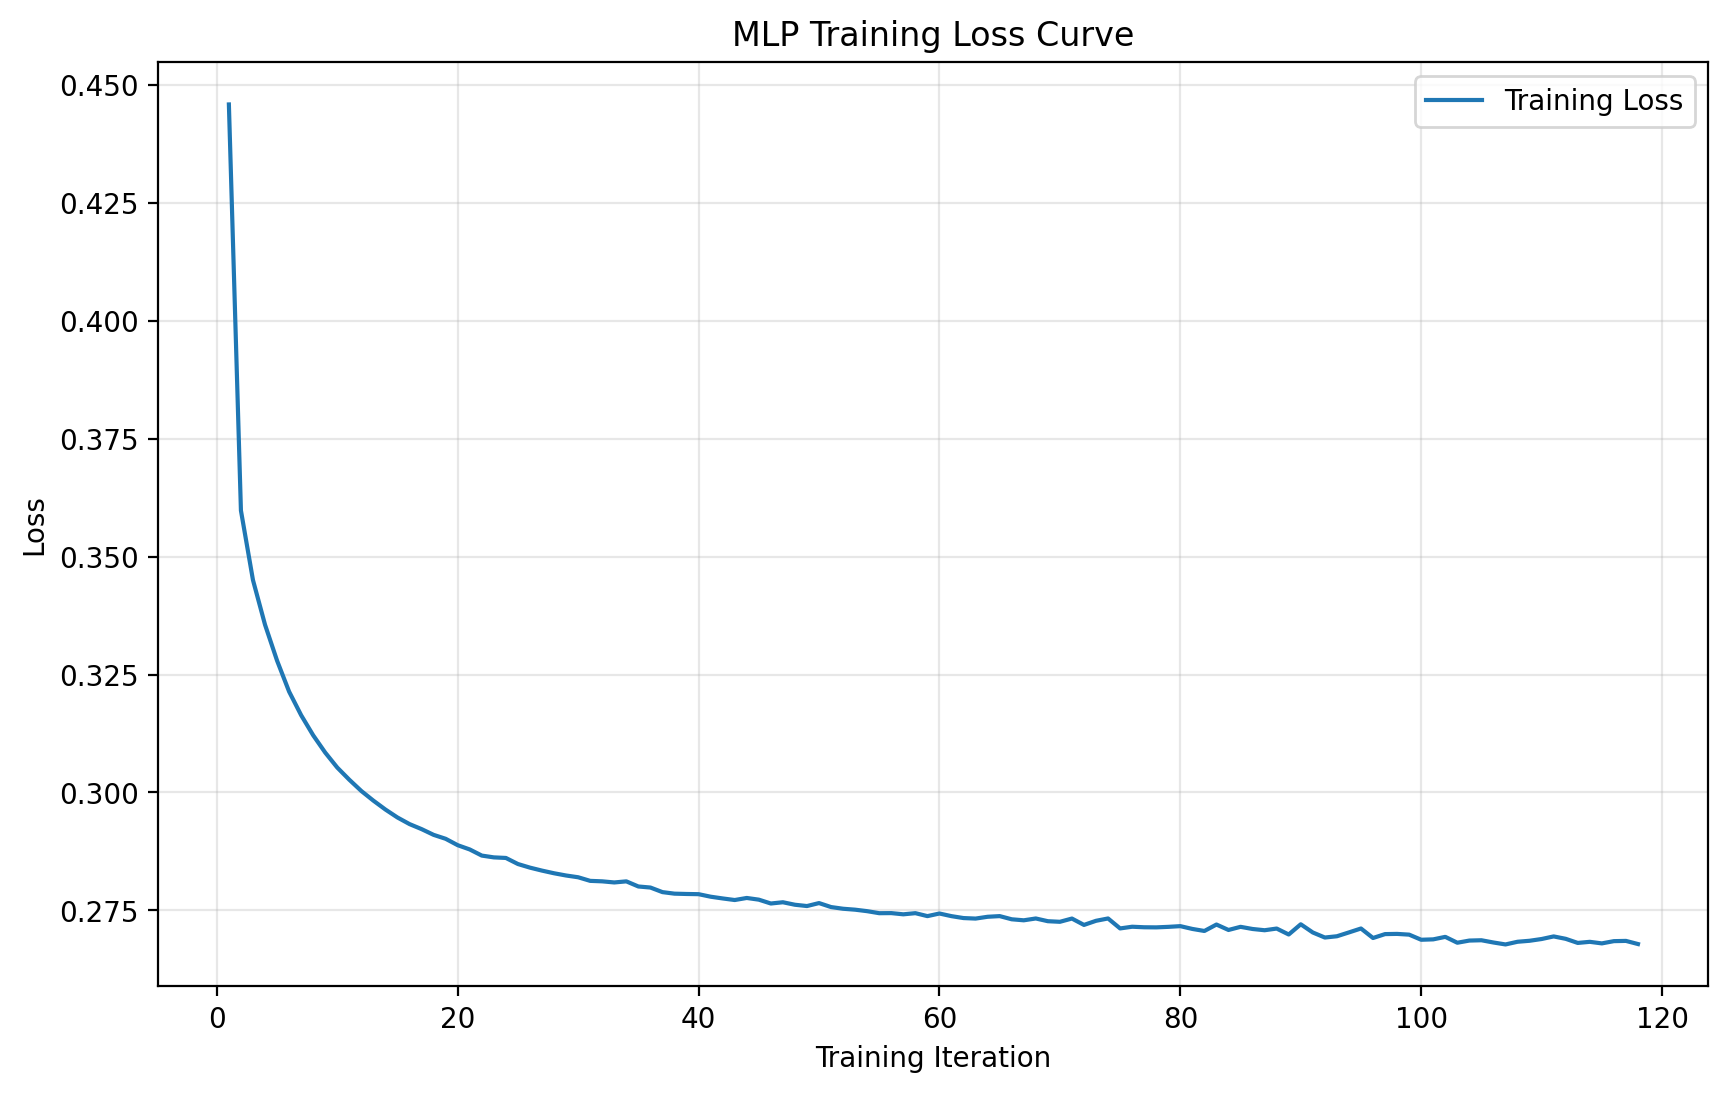

In [414]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(best_mlp_model.loss_curve_) + 1),
    best_mlp_model.loss_curve_,
    label="Training Loss"
)

plt.xlabel("Training Iteration")
plt.ylabel("Loss")
plt.title("MLP Training Loss Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Plot validation performance versus architecture

In [415]:
architecture_results = mlp_results_df[
    mlp_results_df["experiment"].str.startswith("architecture_")
].copy()

architecture_results = architecture_results.sort_values(
    by="validation_AP",
    ascending=False
)

display(
    architecture_results[
        ["hidden_layer_sizes", "validation_AP", "validation_logloss",
         "n_iter", "fit_time_seconds"]
    ].round(4)
)

,hidden_layer_sizes,validation_AP,validation_logloss,n_iter,fit_time_seconds
2,"(64,)",0.4458,0.2873,225,18.9048
6,"(128, 64)",0.3352,0.5518,225,40.1264
7,"(128, 64, 32)",0.3352,1.0129,225,37.9697


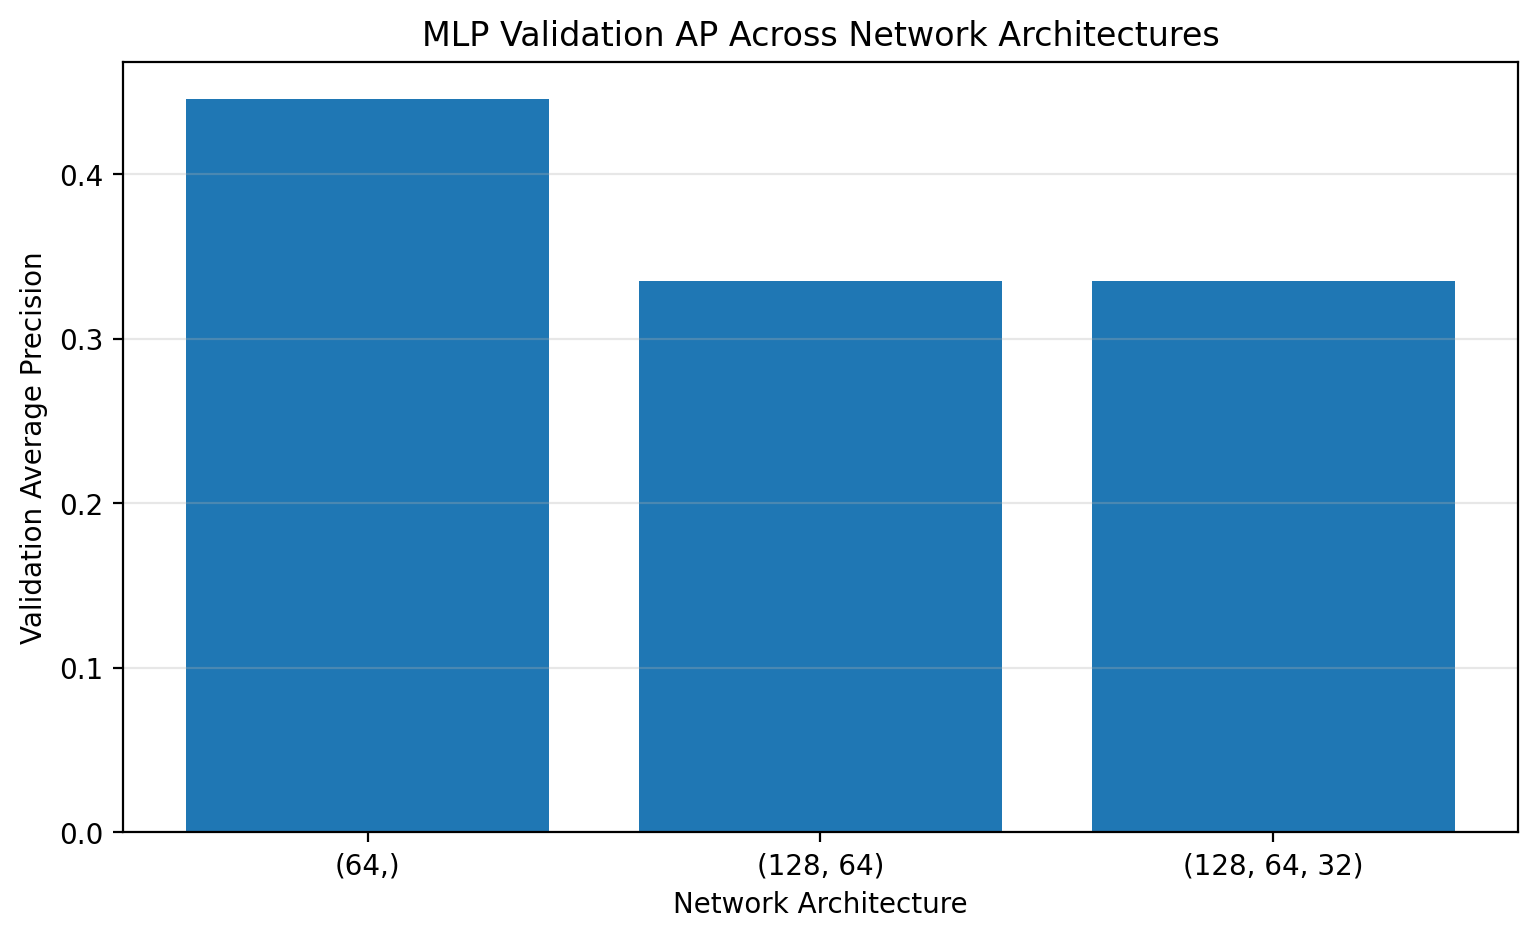

In [416]:
plt.figure(figsize=(9, 5))

plt.bar(
    architecture_results["hidden_layer_sizes"].astype(str),
    architecture_results["validation_AP"]
)

plt.xlabel("Network Architecture")
plt.ylabel("Validation Average Precision")
plt.title("MLP Validation AP Across Network Architectures")
plt.grid(axis="y", alpha=0.3)
plt.show()

## Experiment summary

In [417]:
display(
    mlp_results_df[
        [
            "experiment",
            "hidden_layer_sizes",
            "learning_rate_init",
            "alpha",
            "validation_AP",
            "fit_time_seconds",
            "convergence_warning"
        ]
    ].round(4)
)

,experiment,hidden_layer_sizes,learning_rate_init,alpha,validation_AP,fit_time_seconds,convergence_warning
0,alpha_1.0,"(128, 64)",0.0010,1.0000,0.4777,15.0838,False
1,alpha_5.0,"(128, 64)",0.0010,5.0000,0.4645,8.6622,False
2,"architecture_(64,)","(64,)",0.0010,0.0001,0.4458,18.9048,True
3,learning_rate_0.0003,"(128, 64)",0.0003,0.0001,0.4218,34.5586,True
4,alpha_0.1,"(128, 64)",0.0010,0.1000,0.3664,25.4860,False
5,alpha_0.001,"(128, 64)",0.0010,0.0010,0.3393,31.0254,True
6,"architecture_(128, 64)","(128, 64)",0.0010,0.0001,0.3352,40.1264,True
7,"architecture_(128, 64, 32)","(128, 64, 32)",0.0010,0.0001,0.3352,37.9697,True
8,learning_rate_0.01,"(128, 64)",0.0100,0.0001,0.3302,16.3662,False
9,learning_rate_0.003,"(128, 64)",0.0030,0.0001,0.3040,21.6604,False


# Step 4 Model Evaluation & Comparison

In [418]:
print("===== SELECTED GBDT MODEL =====")
print("Configuration:", best_gbdt_name)
print("Parameters:", best_gbdt_model.get_params())
print("Validation AP:", best_gbdt_result["validation_AP"])

print("\n===== SELECTED MLP MODEL =====")
print("Configuration:", best_mlp_name)
print("Architecture:", best_mlp_model.hidden_layer_sizes)
print("Learning rate:", best_mlp_model.learning_rate_init)
print("Alpha:", best_mlp_model.alpha)
print("Validation AP:", best_mlp_result["validation_AP"])

===== SELECTED GBDT MODEL =====
Configuration: subsample_1.0
Parameters: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': 30, 'enable_categorical': False, 'eval_metric': 'logloss', 'feature_types': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 3, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 3000, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': 1.0, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 1.0, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity': None}
Validation AP: 0.493672267805550

## Test predictions

In [419]:
# GBDT test predictions
gbdt_test_prob = best_gbdt_model.predict_proba(X_test_gbdt)[:, 1]
gbdt_test_pred = (gbdt_test_prob >= 0.5).astype(int)

# MLP test predictions
mlp_test_prob = best_mlp_model.predict_proba(X_test_mlp)[:, 1]
mlp_test_pred = (mlp_test_prob >= 0.5).astype(int)

## Metrics

In [420]:
# Calculate metrics for GBDT
gbdt_metrics = {
    "Accuracy": accuracy_score(y_test, gbdt_test_pred),
    "Precision": precision_score(y_test, gbdt_test_pred, zero_division=0),
    "Recall": recall_score(y_test, gbdt_test_pred, zero_division=0),
    "F1": f1_score(y_test, gbdt_test_pred, zero_division=0),
    "AP": average_precision_score(y_test, gbdt_test_prob)
}

# Calculate metrics for MLP
mlp_metrics = {
    "Accuracy": accuracy_score(y_test, mlp_test_pred),
    "Precision": precision_score(y_test, mlp_test_pred, zero_division=0),
    "Recall": recall_score(y_test, mlp_test_pred, zero_division=0),
    "F1": f1_score(y_test, mlp_test_pred, zero_division=0),
    "AP": average_precision_score(y_test, mlp_test_prob)
}


In [421]:
comparison_df = pd.DataFrame(
    [gbdt_metrics, mlp_metrics],
    index=["GBDT (XGBoost)", "MLP"]
)

comparison_df.index.name = "Model"

display(comparison_df.round(4))

,Accuracy,Precision,Recall,F1,AP
Model,,,,,
GBDT (XGBoost),0.9011,0.6763,0.2342,0.3479,0.4813
MLP,0.9013,0.6569,0.2586,0.3711,0.4730


## Plot Precision-Recall curves

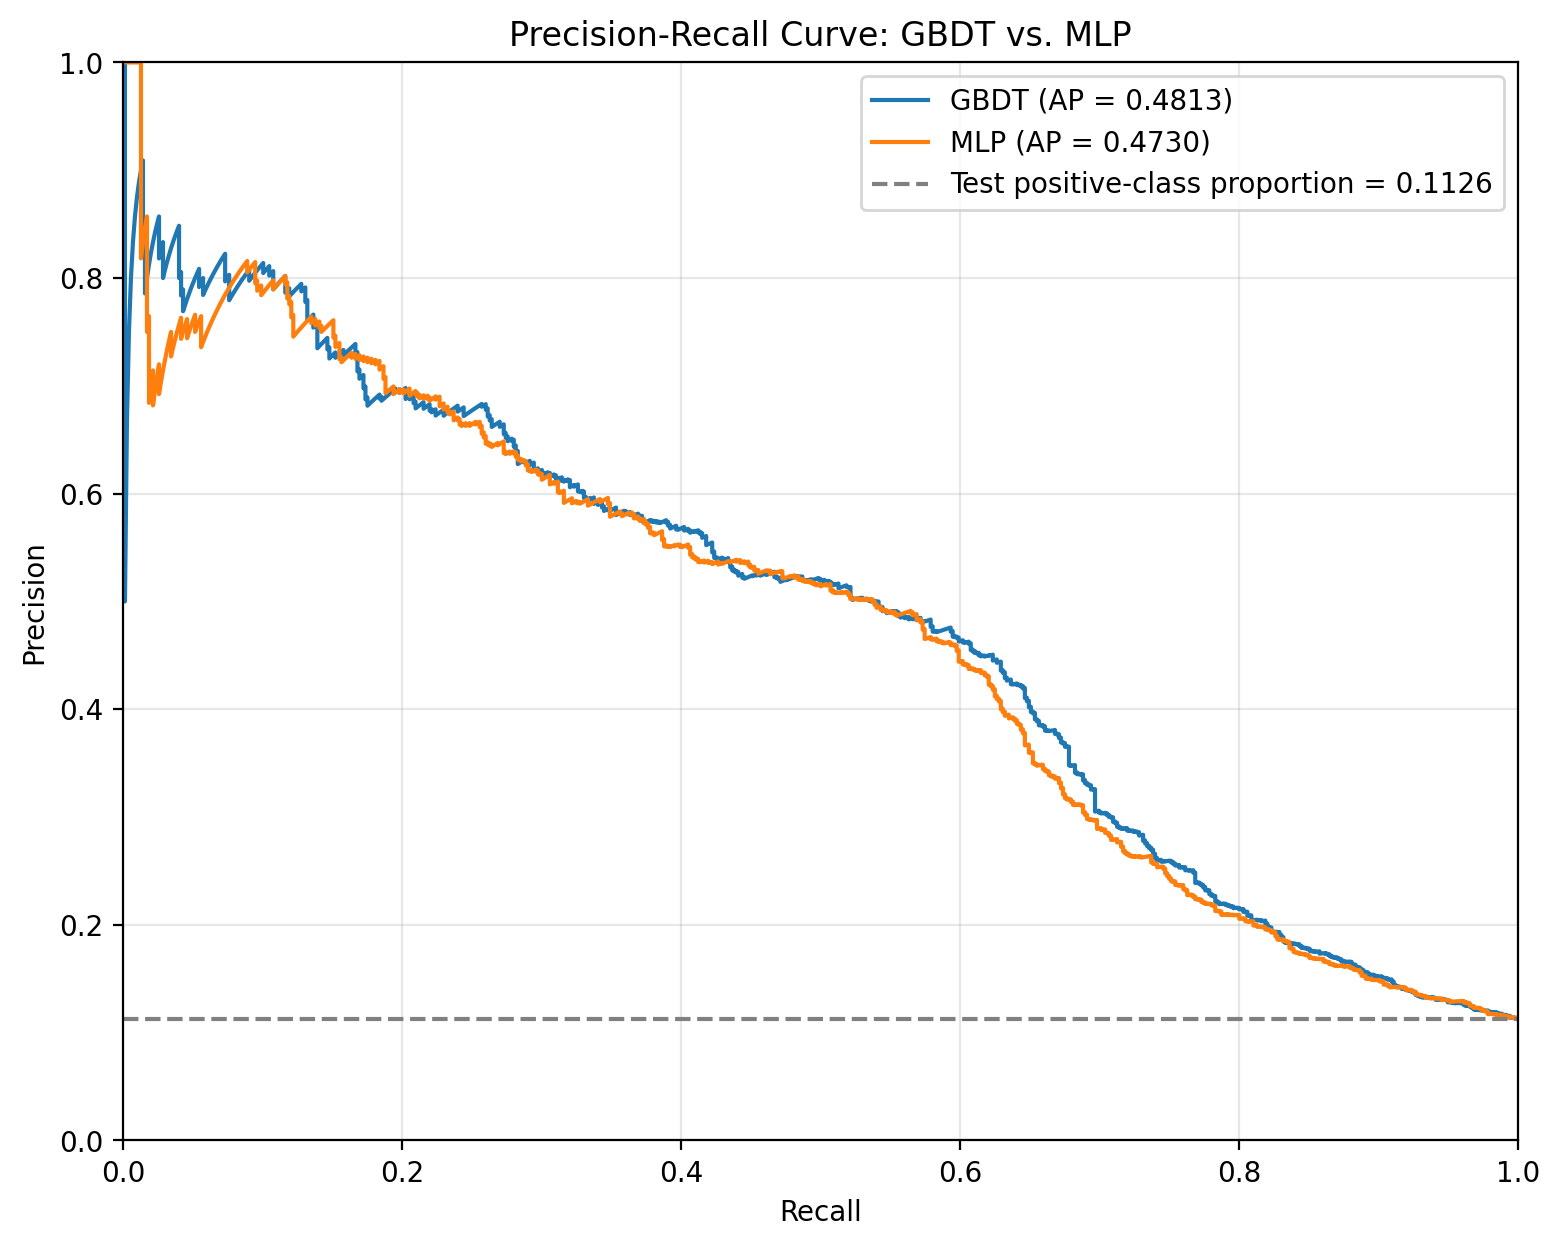

Test positive-class proportion: 11.2640%


In [422]:
# Calculate precision and recall at different thresholds
gbdt_precision, gbdt_recall, _ = precision_recall_curve(
    y_test, gbdt_test_prob
)

mlp_precision, mlp_recall, _ = precision_recall_curve(
    y_test, mlp_test_prob
)

# Test positive-class proportion (reference level)
test_prevalence = y_test.mean()

plt.figure(figsize=(9, 7))

plt.plot(
    gbdt_recall,
    gbdt_precision,
    label=f"GBDT (AP = {gbdt_metrics['AP']:.4f})"
)

plt.plot(
    mlp_recall,
    mlp_precision,
    label=f"MLP (AP = {mlp_metrics['AP']:.4f})"
)

# Random-ranking reference level
plt.axhline(
    y=test_prevalence,
    color="gray",
    linestyle="--",
    label=f"Test positive-class proportion = {test_prevalence:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: GBDT vs. MLP")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

print(f"Test positive-class proportion: {test_prevalence:.4%}")

## Plot confusion matrix

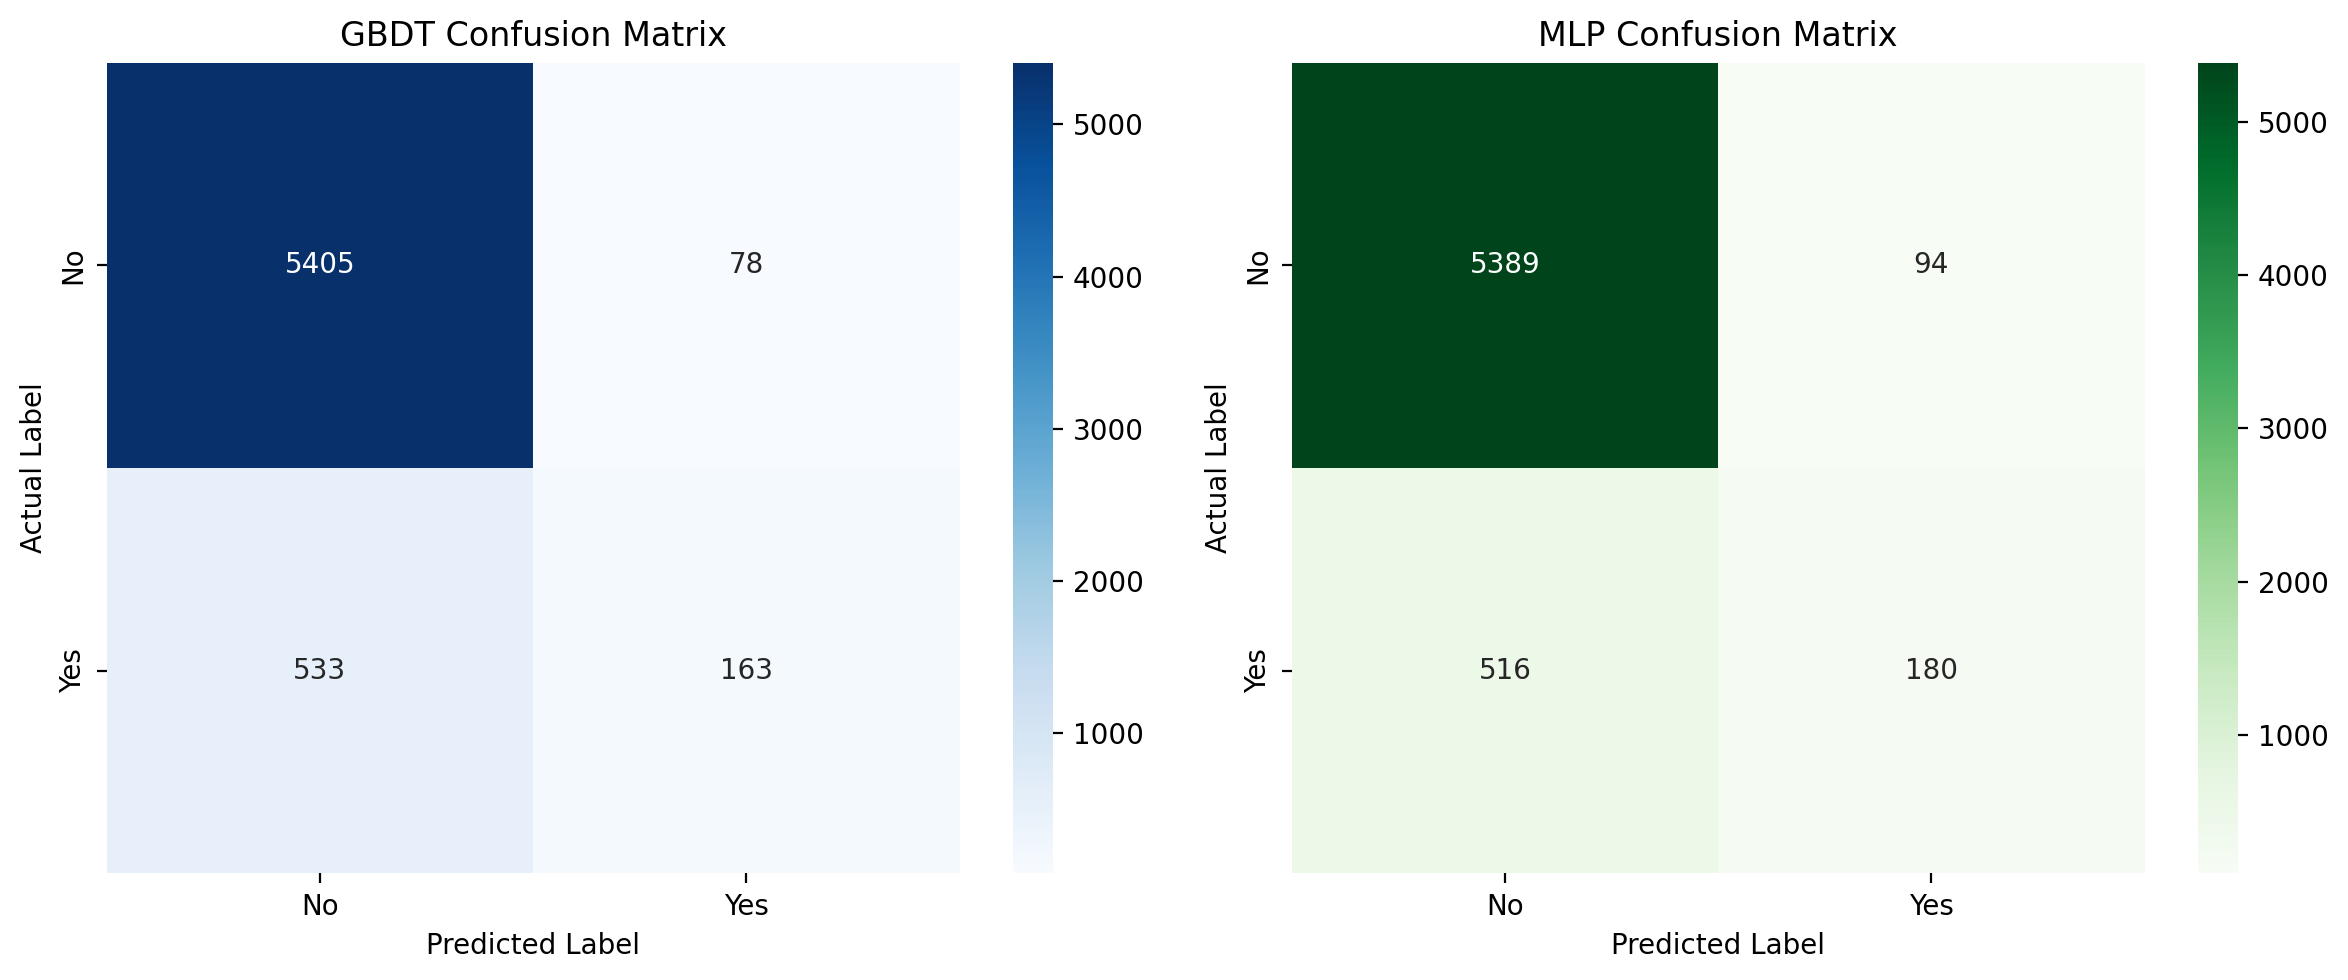

In [423]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

gbdt_cm = confusion_matrix(y_test, gbdt_test_pred)
mlp_cm = confusion_matrix(y_test, mlp_test_pred)

sns.heatmap(
    gbdt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    ax=axes[0]
)

axes[0].set_title("GBDT Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    mlp_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    ax=axes[1]
)

axes[1].set_title("MLP Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

## Compare time

In [424]:
gbdt_fit_time = best_gbdt_result["fit_time_seconds"]
mlp_fit_time = best_mlp_result["fit_time_seconds"]

fit_time_df = pd.DataFrame({
    "Model": ["GBDT (XGBoost)", "MLP"],
    "Final Model Fit Time (seconds)": [
        gbdt_fit_time,
        mlp_fit_time
    ]
})

# Time GBDT preprocessing
gbdt_preprocessor_benchmark = clone(preprocessor_gbdt)

start = time.perf_counter()

gbdt_preprocessor_benchmark.fit_transform(X_train)
gbdt_preprocessor_benchmark.transform(X_val)
gbdt_preprocessor_benchmark.transform(X_test)

gbdt_preprocessing_time = time.perf_counter() - start


# Time MLP preprocessing
mlp_preprocessor_benchmark = clone(preprocessor_mlp)

start = time.perf_counter()

mlp_preprocessor_benchmark.fit_transform(X_train)
mlp_preprocessor_benchmark.transform(X_val)
mlp_preprocessor_benchmark.transform(X_test)

mlp_preprocessing_time = time.perf_counter() - start


# Comparison
timing_df = pd.DataFrame({
    "Model": ["GBDT (XGBoost)", "MLP"],
    "Preprocessing Time (seconds)": [
        gbdt_preprocessing_time,
        mlp_preprocessing_time
    ],
    "Model Fit Time (seconds)": [
        gbdt_fit_time,
        mlp_fit_time
    ]
})

display(timing_df.round(4))

,Model,Preprocessing Time (seconds),Model Fit Time (seconds)
0,GBDT (XGBoost),0.1849,0.5077
1,MLP,0.0779,15.0838


## Hardware, seeds, package

In [425]:
print("===== EXPERIMENTAL ENVIRONMENT =====")

print("Python:", platform.python_version())
print("Operating system:", platform.platform())
print("Processor:", platform.processor())
print("CPU cores:", os.cpu_count())

print("\n===== PACKAGE VERSIONS =====")

print("XGBoost:", xgb.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("\n===== EXPERIMENT SETTINGS =====")

print("Random seed:", RANDOM_STATE)
print("GBDT tree method: hist")
print("GBDT device: CPU")
print("MLP solver: adam")
print("MLP early stopping: False")

===== EXPERIMENTAL ENVIRONMENT =====
Python: 3.10.7
Operating system: macOS-26.5.2-arm64-arm-64bit
Processor: arm
CPU cores: 8

===== PACKAGE VERSIONS =====
XGBoost: 2.1.4
Scikit-learn: 1.5.2
Pandas: 2.2.3
NumPy: 1.26.4

===== EXPERIMENT SETTINGS =====
Random seed: 42
GBDT tree method: hist
GBDT device: CPU
MLP solver: adam
MLP early stopping: False
